# Reto Planta Física · Entregable 1: Investigación

Diseño de algoritmos matemáticos bioinspirados ·MA2015 · Grupo 201

**Integrantes**

* Elisa Jiménez Calderón · A01668464
* Sofía Becerra Pedraza · A01661775
* Cecilia Correa Gálvez · A01754061

Esta libreta acumulativa parte de la **base común** proporcionada por el docente (secciones numeradas 1–12).

### Rotación de responsabilidades

| Avance | Programación | Revisión | Verificación |
| --- | --- | --- | --- |
| Investigación | Todo el equipo | Elisa & Cecilia | Sofía |
| Desarrollo | (por asignar) | (por asignar) | (por asignar) |
| Final | (por asignar) | (por asignar) | (por asignar) |


## 1. Definimos el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como **capacidad didáctica**, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60% de reúso. Hay $9\times9\times7\times9=5103$ combinaciones; exploramos algunas mediante el algoritmo genético.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## Formulación y supuestos

### Caso
Planta Física del Campus Ciudad de México debe decidir, para **un mes** (marzo de 2025), qué parte de la demanda de agua de cuatro edificios se cubre con **agua tratada**; el resto se cubre con **agua potable**. Buscamos usar la menor cantidad posible de agua potable sin exceder la capacidad de agua tratada.

### Cromosoma, genes y decisión que representa cada gen
Un candidato es el **cromosoma** $k=(k_1,k_2,k_3,k_4)$, con **cuatro genes enteros** en el orden fijo de la tabla. Cada gen $k_i$ es un nivel discreto y su fracción es $x_i = k_i/10$ (adimensional; $100x_i$ es el porcentaje).

| Gen | Edificio | Dominio | Fracción | Decisión que representa |
| --- | --- | --- | --- | --- |
| $k_1$ | Aulas 1 | $\{0,\ldots,8\}$ | $x_1\le 0.8$ | Qué fracción de la demanda mensual de Aulas 1 se abastece con agua tratada |
| $k_2$ | Biblioteca | $\{0,\ldots,8\}$ | $x_2\le 0.8$ | Qué fracción de la demanda mensual de Biblioteca se abastece con agua tratada |
| $k_3$ | Cedetec | $\{0,\ldots,6\}$ | $x_3\le 0.6$ | Qué fracción de la demanda mensual de Cedetec se abastece con agua tratada |
| $k_4$ | Aulas 2 | $\{0,\ldots,8\}$ | $x_4\le 0.8$ | Qué fracción de la demanda mensual de Aulas 2 se abastece con agua tratada |

Por ejemplo, $k_3=6$ significa que 60 % de la demanda de Cedetec se cubre con agua tratada y el 40 % restante con agua potable. Hay $9\times9\times7\times9=5103$ cromosomas posibles. Una codificación fuera de estos dominios o no entera se **rechaza** (no se redondea ni se corrige).

### Datos observados (consumos reales)

| Edificio | Demanda $D_i$ (m³) |
| --- | --- |
| Aulas 1 | 847.00 |
| Biblioteca | 462.00 |
| Cedetec | 284.21 |
| Aulas 2 | 683.00 |
| **Total** $Q=\sum_i D_i$ | **2276.21** |

Son las demandas agregadas reales de **marzo de 2025** tomadas de `consumo_agua_2023_2026.csv` (repositorio técnico MA2015-Planta-Física). Los cuatro registros no tienen banderas de imputación, cero ni anomalía. La metadata de esta libreta conserva los registros y los hashes de procedencia de las fuentes.

### Supuestos didácticos
* **Capacidad** $C = 1410$ m³/mes de agua tratada, tomada de `parametros_reto.csv` y calibrada por el docente; **no** es una capacidad confirmada por el socio.
* **Límites por edificio** (80 %, 80 %, 60 %, 80 %): definen los dominios de los genes y también son didácticos.
* El horizonte es **mensual** y las demandas son agregadas; el modelo no representa variación diaria, presiones, calidad del agua ni operación real. Los resultados describen un modelo académico, no una solución hidráulica o sanitaria validada.
* Tolerancia numérica de $10^{-8}$ m³ al comparar con la capacidad.

### Problema de optimización
Volúmenes (todos en m³ por mes):

$$T_i = D_i\,\frac{k_i}{10},\qquad T=\sum_{i=1}^{4} T_i,\qquad P = Q - T,\qquad E=\max(0,\;T-C).$$

$$\min_{k}\; P \quad \text{sujeto a}\quad k_1,k_2,k_4\in\{0,\ldots,8\},\; k_3\in\{0,\ldots,6\},\quad T\le C\;(+10^{-8}).$$

Los **dominios** limitan cada edificio por separado; la **capacidad** limita la suma de los cuatro. Los operadores conservan los dominios y el evaluador distingue la capacidad.

### Aptitud (adimensional, menor es mejor)

$$F(k)=\begin{cases}\dfrac{P}{Q}, & T\le C+10^{-8}\ \text{(factible)}\\[2mm] 1+\dfrac{E}{C}, & T> C+10^{-8}\ \text{(infactible)}\end{cases}$$

Un candidato factible tiene $F\le 1$ y uno infactible $F>1$, por lo que todo plan factible queda por delante de cualquier infactible. Entre factibles, menos agua potable implica menor $F$.

## 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. **Menor aptitud es mejor.** Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

Antes de ejecutar, calcula a mano $k=(6,6,6,6)$: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explica por qué cumple la capacidad y qué unidad tiene cada resultado.

In [2]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

Comprueba tres candidatos: cero reúso, 60% uniforme y máximos del dominio. Distingue cumplir el dominio de cumplir la capacidad. Las claves `treated`, `potable`, `excess`, `feasible` y `fitness` corresponden a $T$, $P$, $E$, factibilidad y $F$.

In [3]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


Interpretamos: el plan máximo usa 1764.126 m³ tratados, excede la capacidad en 354.126 m³ y obtiene $F>1$. Aunque reduce más el agua potable, lo descartamos por infactible. Conserva el cálculo manual y la explicación de tu equipo como evidencia de Investigación.

## [Equipo] Manual

Calculamos a mano dos candidatos: el reúso uniforme de 60 % y el plan con todos los genes en su máximo. Las fotografías muestran el procedimiento escrito; las tablas resumen la aritmética.

### Candidato 1: $k=(6,6,6,6)$

| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i=D_ix_i$ (m³) | $P_i=D_i-T_i$ (m³) |
| --- | --- | --- | --- | --- | --- |
| Aulas 1 | 847.00 | 6 | 0.6 | 508.200 | 338.800 |
| Biblioteca | 462.00 | 6 | 0.6 | 277.200 | 184.800 |
| Cedetec | 284.21 | 6 | 0.6 | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 6 | 0.6 | 409.800 | 273.200 |
| **Total** | **2276.21** | | | **T = 1365.726** | **P = 910.484** |

* $T = 508.2+277.2+170.526+409.8 = 1365.726$ m³ $= 0.6\times2276.21$.
* $P = 2276.21-1365.726 = 910.484$ m³.
* $T=1365.726\le C=1410$: **factible**, con un margen de $1410-1365.726=44.274$ m³ sin usar. Por eso $E=\max(0,\,-44.274)=0$ m³.
* $F = P/Q = 910.484/2276.21 = 0.4$ (adimensional): 40 % de la demanda total sigue cubriéndose con agua potable.

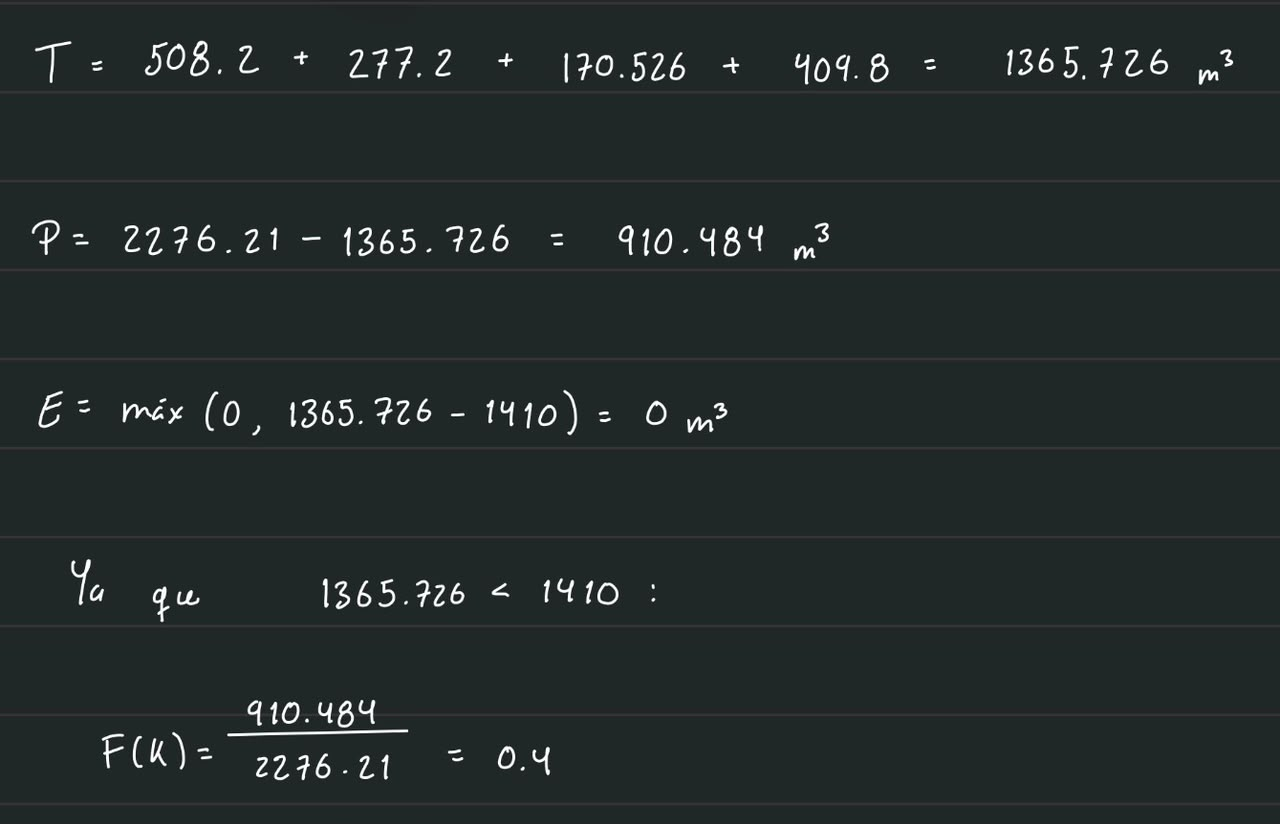

### Candidato 2 (plan máximo): $k=(8,8,6,8)$

| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i=D_ix_i$ (m³) | $P_i=D_i-T_i$ (m³) |
| --- | --- | --- | --- | --- | --- |
| Aulas 1 | 847.00 | 8 | 0.8 | 677.600 | 169.400 |
| Biblioteca | 462.00 | 8 | 0.8 | 369.600 | 92.400 |
| Cedetec | 284.21 | 6 | 0.6 | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 8 | 0.8 | 546.400 | 136.600 |
| **Total** | **2276.21** | | | **T = 1764.126** | **P = 512.084** |

* $T = 677.6+369.6+170.526+546.4 = 1764.126$ m³ $> C=1410$ m³: **infactible**.
* $E = 1764.126-1410 = 354.126$ m³.
* $F = 1 + E/C = 1 + 354.126/1410 \approx 1.2512 > 1$.

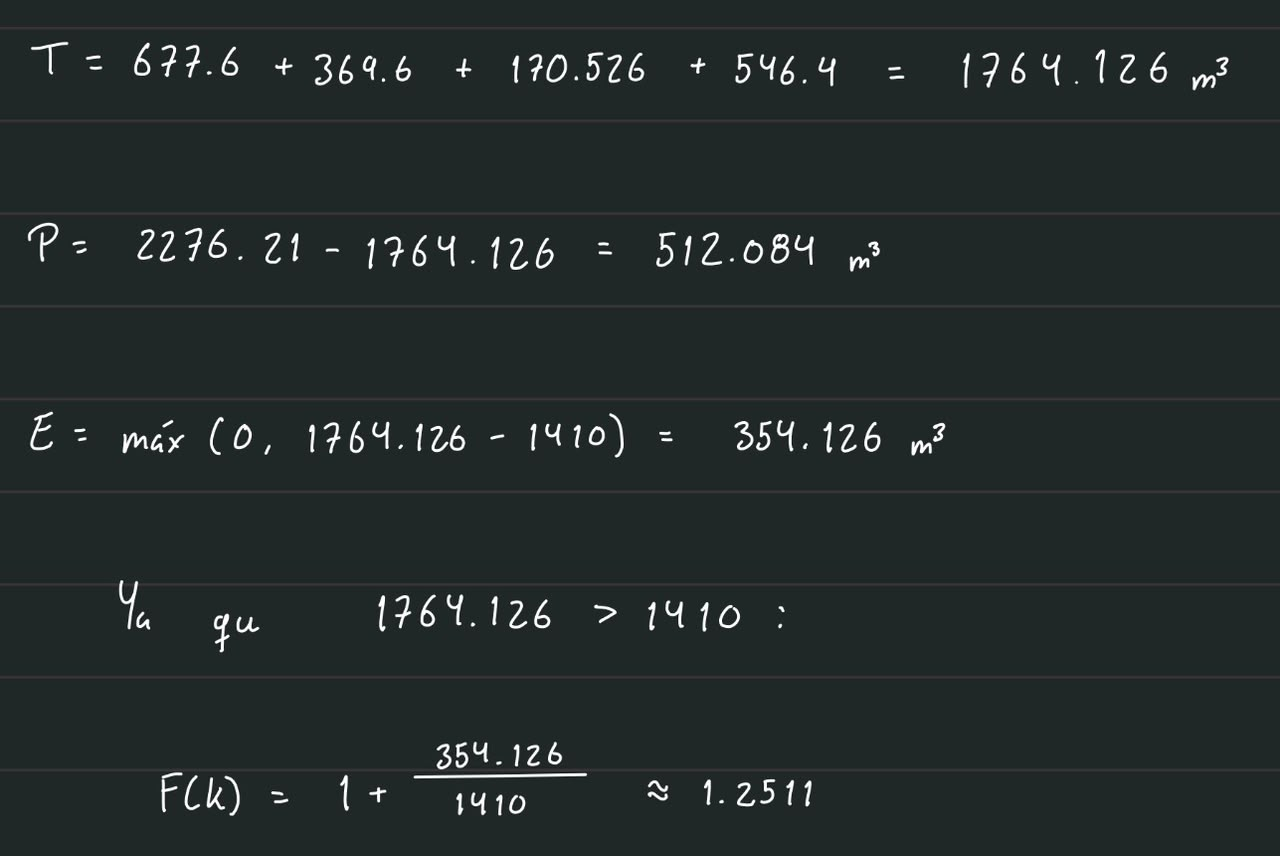

## [Equipo] Comprobación con el evaluador

Usamos `evaluate` de la base común (sección 2) para contrastar los valores calculados a mano.

In [4]:
resultado = evaluate(np.array([6, 6, 6, 6]))
manual_6 = dict(treated=1365.726, potable=910.484, excess=0.0, fitness=0.4, feasible=True)
nombres = dict(treated="T (m³)", potable="P (m³)", excess="E (m³)", fitness="F")

print(f"{'Métrica':<10}{'Manual':>12}{'evaluate':>22}{'Diferencia':>12}")
for clave, nombre in nombres.items():
    dif = resultado[clave] - manual_6[clave]
    print(f"{nombre:<10}{manual_6[clave]:>12.3f}{resultado[clave]:>22.13f}{dif:>12.1e}")
print(f"{'Factible':<10}{str(manual_6['feasible']):>12}{str(resultado['feasible']):>22}",
      "coinciden" if manual_6["feasible"] == resultado["feasible"] else "NO coinciden")

Métrica         Manual              evaluate  Diferencia
T (m³)        1365.726    1365.7259999999999    -2.3e-13
P (m³)         910.484     910.4840000000002     1.1e-13
E (m³)           0.000       0.0000000000000     0.0e+00
F                0.400       0.4000000000000     5.6e-17
Factible          True                  True coinciden


In [5]:
manual = {
    (6, 6, 6, 6): dict(treated=1365.726, potable=910.484, excess=0.0,
                       feasible=True, fitness=910.484 / 2276.21),
    (8, 8, 6, 8): dict(treated=1764.126, potable=512.084, excess=354.126,
                       feasible=False, fitness=1 + 354.126 / 1410),
}

for genes, esperado in manual.items():
    k = np.array(genes)
    r = evaluate(k)
    print(genes, "T_i (m³) =", DEMAND * k / 10)
    print({clave: (round(v, 4) if isinstance(v, float) else v) for clave, v in r.items()})
    for clave, valor in esperado.items():
        assert np.isclose(r[clave], valor), clave

print("El cálculo manual coincide con evaluate.")

(6, 6, 6, 6) T_i (m³) = [508.2   277.2   170.526 409.8  ]
{'treated': 1365.726, 'potable': 910.484, 'excess': 0.0, 'feasible': True, 'fitness': 0.4}
(8, 8, 6, 8) T_i (m³) = [677.6   369.6   170.526 546.4  ]
{'treated': 1764.126, 'potable': 512.084, 'excess': 354.126, 'feasible': False, 'fitness': 1.2512}
El cálculo manual coincide con evaluate.


In [6]:
# Una codificación inválida se rechaza; no se redondea ni se corrige.
for invalido in (np.array([9, 0, 0, 0]), np.array([0, 0, 7, 0]), np.array([6.0, 6.0, 6.0, 6.0])):
    try:
        evaluate(invalido)
    except ValueError as error:
        print(invalido, "→ rechazado:", error)

[9 0 0 0] → rechazado: Genes outside the allowed building domains.
[0 0 7 0] → rechazado: Genes outside the allowed building domains.
[6. 6. 6. 6.] → rechazado: Expected four integer genes in building order.


## [Equipo] Interpretación

### Coincidencias
El cálculo manual y `evaluate` coinciden porque usan los mismos datos (demandas de marzo de 2025 y $C=1410$ m³) y las mismas fórmulas:

* **Agua tratada por edificio:** `DEMAND * genes / 10` calcula $T_i = D_i k_i/10$; `np.sum` da $T$.
* **Agua potable:** `np.sum(DEMAND) - treated` calcula $P = Q - T$.
* **Exceso:** `max(0.0, treated - CAPACITY)` calcula $E=\max(0,T-C)$.
* **Factibilidad:** `excess <= 1e-8` comprueba $T\le C$ con la tolerancia de $10^{-8}$ m³.
* **Aptitud:** `fitness` aplica $P/Q$ si es factible o $1+E/C$ si excede la capacidad.

El cromosoma y `DEMAND` siguen el mismo orden (Aulas 1, Biblioteca, Cedetec, Aulas 2), así que cada gen multiplica la demanda de su edificio.

### Diferencias por punto flotante
`evaluate` muestra valores como `1365.7259999999999` y `0.4000000000000001` porque algunos decimales (0.6, 284.21) no tienen representación binaria exacta. Las diferencias son del orden de $10^{-13}$, muy por debajo de la tolerancia de $10^{-8}$ m³, así que no cambian la factibilidad ni la rama de aptitud. Redondeados a tres decimales, los valores son idénticos a los manuales; **no fue necesario corregir ningún valor**.

### ¿Por qué el plan máximo es infactible aunque respeta los dominios?
En $(8,8,6,8)$ cada gen está en el límite superior de su dominio ($8\le8$, $8\le8$, $6\le6$, $8\le8$), por lo que la codificación es válida y `evaluate` no la rechaza. Pero los dominios limitan a **cada edificio por separado**, mientras que la capacidad limita la **suma de los cuatro**: $T=1764.126$ m³ supera $C=1410$ m³ por $E=354.126$ m³. Físicamente, el plan pide 354.126 m³ de agua tratada que la planta (con la capacidad supuesta) no puede suministrar en el mes.

Aunque este plan usaría menos agua potable (512.084 m³ frente a 910.484 m³), recibe $F\approx1.2512>1$, por lo que cualquier plan factible, como $(6,6,6,6)$ con $F=0.4$, queda mejor ordenado. Respetar los dominios no garantiza cumplir la capacidad: por eso el algoritmo genético deberá buscar combinaciones que aprovechen el margen disponible (en $(6,6,6,6)$ aún quedan 44.274 m³) sin pasar de 1410 m³.

## 3. Generamos una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [7]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. Seleccionamos padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [8]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. Combinamos información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [9]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. Introducimos variación con mutación

Aplicamos la probabilidad a **cada gen**, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [10]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. Reemplazamos la población y conservamos una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [11]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. Cerramos el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [12]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. Ejecuta una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [13]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Visualizamos e interpretamos

Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora; una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

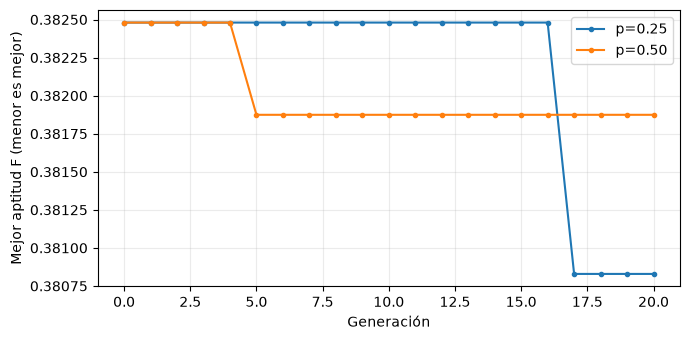

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Conserva la interpretación de tu equipo en una celda: identifica el parámetro cambiado; compara el mejor $F$, el agua potable y la factibilidad; explica una meseta o mejora; y delimita lo que puedes concluir de dos ejecuciones. Si los resultados coinciden, explica esa coincidencia con la misma validez. La variación no necesita ganar.

## 11. Comprueba reproducción

Repite la configuración base con la misma semilla y comprueba igualdad de genes e historia. Reinicia el kernel y ejecuta de arriba abajo para descartar dependencias de ejecuciones previas. Esta repetición es una comprobación técnica, no una tercera configuración experimental.

In [15]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


## 12. Conserva evidencia en la misma libreta

- **Investigación (15%)**: formulación y supuestos (60/100); cálculo manual y contraste con el evaluador (40/100).
- **Desarrollo (15%)**: ciclo y operadores funcionales (70/100); una ejecución reproducible e interpretada (30/100).
- **Entrega final (30%)**: explicación de una generación (40/100); dos configuraciones y gráfica (35/100); interpretación física y límites (25/100).

En la entrega final reutiliza las secciones anteriores y añade la explicación de tu equipo. Identifica la base común y cualquier cambio propio. Las funciones adicionales no son necesarias para obtener 100. Conserva los archivos de entorno proporcionados junto a la libreta. La evaluación conjunta del código aporta 10% y el examen individual de artículos 30%. Consulta niveles y fechas en la [guía](guia_reto_planta_fisica.pdf).

## Procedencia y entorno

Usamos `assets/kit/datos/consumo_agua_2023_2026.csv` y `assets/kit/parametros_reto.csv` del repositorio técnico MA2015-Planta-Fisica, filtrados a marzo de 2025. La metadata conserva los cuatro registros y los hashes de las fuentes completas. El caso mensual y el código son autónomos.

Con Python 3.12–3.14 y los archivos proporcionados, prepara el entorno con `uv sync --locked` y abre Jupyter con `uv run jupyter lab`. NumPy realiza los cálculos y Matplotlib dibuja la gráfica. Los resultados representan este modelo didáctico, no una recomendación hidráulica o sanitaria validada.